# Trabajo Práctico - Métricas de regresión

**ITSE - Tecnicatura Superior en Ciencia de Datos e Inteligencia Artificial**
**Unidad 3: Modelos de Regresión**

**Guía de Trabajos Prácticos: Algoritmos de regresión sobre datasets públicos**

Se evalúan los modelos de regresión con las métricas de calidad estándar y se elige el modelo más conveniente para cada problema.

**Consigna general**
1. Calcular para cada modelo las métricas **MAE**, **RMSE** y **R²** sobre el conjunto de prueba.
2. Comparar los resultados en una tabla y elegir el modelo más conveniente, justificando la elección en función de las métricas *y* del contexto del problema (no solo del valor numérico más alto o más bajo).
3. Redactar una conclusión breve (media carilla) indicando ventajas, limitaciones y posibles mejoras (variables, datos, otros algoritmos).

**Métricas utilizadas**
- **MAE** (Error Absoluto Medio): error promedio en las mismas unidades que la variable objetivo.
- **RMSE** (Raíz del Error Cuadrático Medio): penaliza más los errores grandes; útil para detectar predicciones muy alejadas.
- **R²** (Coeficiente de Determinación): proporción de la varianza explicada por el modelo.

In [1]:
# Imports
import io, zipfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_predict, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import warnings
warnings.filterwarnings("ignore")
%matplotlib inline
SEED = 42

pd.set_option("display.float_format", lambda v: f"{v:,.4f}")


def get_modelos():
    # set de algoritmos de regresion a comparar
    return {
        "Regresion lineal": Pipeline([("scaler", StandardScaler()), ("model", LinearRegression())]),
        "Ridge": Pipeline([("scaler", StandardScaler()), ("model", Ridge(alpha=1.0))]),
        "Lasso": Pipeline([("scaler", StandardScaler()), ("model", Lasso(alpha=1.0, max_iter=20000))]),
        "KNN": Pipeline([("scaler", StandardScaler()), ("model", KNeighborsRegressor(n_neighbors=10))]),
        "Arbol de decision": DecisionTreeRegressor(random_state=SEED),
        "Random Forest": RandomForestRegressor(n_estimators=200, random_state=SEED, n_jobs=-1),
        "Gradient Boosting": GradientBoostingRegressor(random_state=SEED),
    }


def evaluar_modelos(X_train, X_test, y_train, y_test, titulo):
    # entrena todos los modelos y devuelve la tabla comparativa de metricas
    filas = []
    for nombre, modelo in get_modelos().items():
        modelo.fit(X_train, y_train)
        y_pred = modelo.predict(X_test)
        filas.append({
            "Modelo": nombre,
            "MAE": mean_absolute_error(y_test, y_pred),
            "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
            "R2": r2_score(y_test, y_pred),
        })
    tabla = (pd.DataFrame(filas)
             .sort_values("RMSE")
             .reset_index(drop=True))
    print(titulo)
    display(tabla.style.format({"MAE": "{:,.3f}", "RMSE": "{:,.3f}", "R2": "{:,.4f}"})
            .hide(axis="index")
            .set_caption("Tabla comparativa de metricas (conjunto de prueba)"))
    print(tabla_md(tabla))
    return tabla


def tabla_md(df):
    # devuelve la tabla en formato Markdown (para copiar al informe)
    cols = list(df.columns)
    out = ["| " + " | ".join(cols) + " |",
           "|" + "|".join(["---"] * len(cols)) + "|"]
    for _, fila in df.iterrows():
        vals = []
        for col in cols:
            v = fila[col]
            vals.append(f"{v:,.4f}" if isinstance(v, float) else str(v))
        out.append("| " + " | ".join(vals) + " |")
    return "\n".join(out)

---

## Ejercicio 1 - Predicción de la demanda de bicicletas compartidas

**Dataset:** [Bike Sharing Dataset (UCI)](https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset) - registros horarios de alquiler de bicicletas en Washington D.C. (2011-2012).

- **17.379 filas**, 17 columnas.
- **Variable objetivo:** `cnt` = cantidad total de bicicletas alquiladas en la hora (media 189, máx 977).
- **Predictores:** estación, año, mes, hora, feriado, día de la semana, día laborable, situación meteorológica (`weathersit`: 1 despejado, 2 nublado, 3 lluvia/nieve ligera, 4 lluvia fuerte), temperatura y sensación térmica (normalizadas), humedad y velocidad del viento.

In [2]:
# Carga del dataset desde UCI
URL_BIKE = "https://archive.ics.uci.edu/ml/machine-learning-databases/00275/Bike-Sharing-Dataset.zip"

zip_bytes = urllib.request.urlopen(URL_BIKE, timeout=90).read()
zf = zipfile.ZipFile(io.BytesIO(zip_bytes))
print("Archivos del zip:", zf.namelist())

df_bike = pd.read_csv(zf.open("hour.csv"))
df_bike.head()

Archivos del zip: ['Readme.txt', 'day.csv', 'hour.csv']


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.2400,0.2879,0.8100,0.0000,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.2200,0.2727,0.8000,0.0000,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.2200,0.2727,0.8000,0.0000,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.2400,0.2879,0.7500,0.0000,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.2400,0.2879,0.7500,0.0000,0,1,1


Filas y columnas: (17379, 17)

Columnas: ['instant', 'dteday', 'season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt']

Valores nulos por columna:
 instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0

Situacion meteorologica:
 weathersit
1    11413
2     4544
3     1419
4        3

Estadisticas de la variable objetivo (cnt):


,cnt
count,"17,379.0000"
mean,189.4631
std,181.3876
min,1.0000
25%,40.0000
50%,142.0000
75%,281.0000
max,977.0000


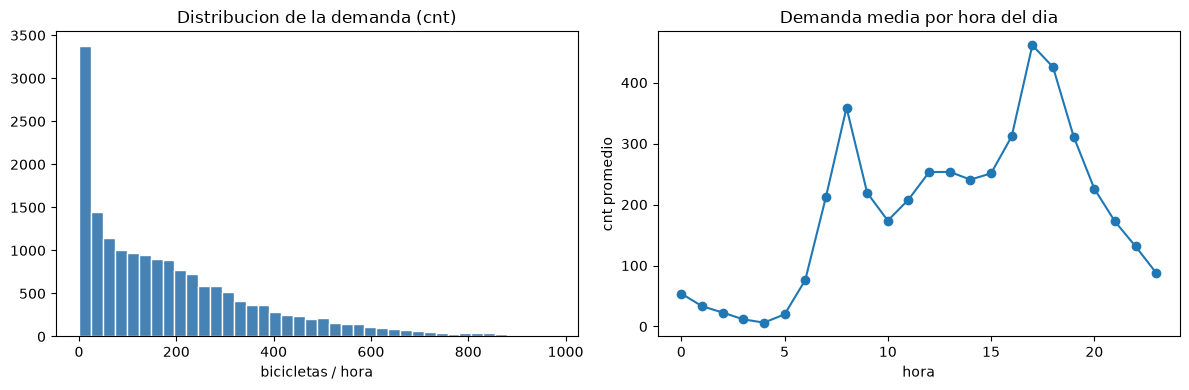

In [3]:
# Exploracion inicial
print("Filas y columnas:", df_bike.shape)
print("\nColumnas:", df_bike.columns.tolist())
print("\nValores nulos por columna:\n", df_bike.isna().sum().to_string())
print("\nSituacion meteorologica:\n", df_bike["weathersit"].value_counts().sort_index().to_string())
print("\nEstadisticas de la variable objetivo (cnt):")
display(df_bike[["cnt"]].describe())

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(df_bike["cnt"], bins=40, color="steelblue", edgecolor="white")
ax[0].set_title("Distribucion de la demanda (cnt)")
ax[0].set_xlabel("bicicletas / hora")
ax[1].plot(df_bike.groupby("hr")["cnt"].mean(), marker="o")
ax[1].set_title("Demanda media por hora del dia")
ax[1].set_xlabel("hora"); ax[1].set_ylabel("cnt promedio")
plt.tight_layout(); plt.show()

**Preparación de los datos**

- Se elimina `casual` y `registered`: sumadas dan exactamente `cnt`, usarlas sería *data leakage* (trampa de información).
- Se elimina `instant` (número de registro, no aporta) y `dteday` (fecha, ya representada por `yr`, `mnth`, `weekday`).
- Split **80% train / 20% test** con `random_state=42` para que sea reproducible.

In [4]:
df1 = df_bike.drop(columns=["casual", "registered", "instant", "dteday"])

X1 = df1.drop(columns=["cnt"])
y1 = df1["cnt"]

X1_train, X1_test, y1_train, y1_test = train_test_split(
    X1, y1, test_size=0.2, random_state=SEED)

print("Train:", X1_train.shape, "| Test:", X1_test.shape)
print("Variables predictoras:", X1_train.columns.tolist())

Train: (13903, 12) | Test: (3476, 12)
Variables predictoras: ['season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed']


### Comparación de modelos (MAE, RMSE, R²)

In [5]:
tabla1 = evaluar_modelos(X1_train, X1_test, y1_train, y1_test,
                         "EJERCICIO 1 - Demanda de bicicletas (target: cnt)")

EJERCICIO 1 - Demanda de bicicletas (target: cnt)


Modelo,MAE,RMSE,R2
Random Forest,24.723,41.797,0.9448
Arbol de decision,34.180,58.249,0.8929
Gradient Boosting,47.149,69.040,0.8495
KNN,74.152,106.354,0.6428
Regresion lineal,104.803,139.211,0.3880
Ridge,104.803,139.212,0.3880
Lasso,104.551,139.218,0.3879


| Modelo | MAE | RMSE | R2 |
|---|---|---|---|
| Random Forest | 24.7226 | 41.7965 | 0.9448 |
| Arbol de decision | 34.1801 | 58.2486 | 0.8929 |
| Gradient Boosting | 47.1487 | 69.0403 | 0.8495 |
| KNN | 74.1519 | 106.3537 | 0.6428 |
| Regresion lineal | 104.8034 | 139.2115 | 0.3880 |
| Ridge | 104.8031 | 139.2115 | 0.3880 |
| Lasso | 104.5508 | 139.2179 | 0.3879 |


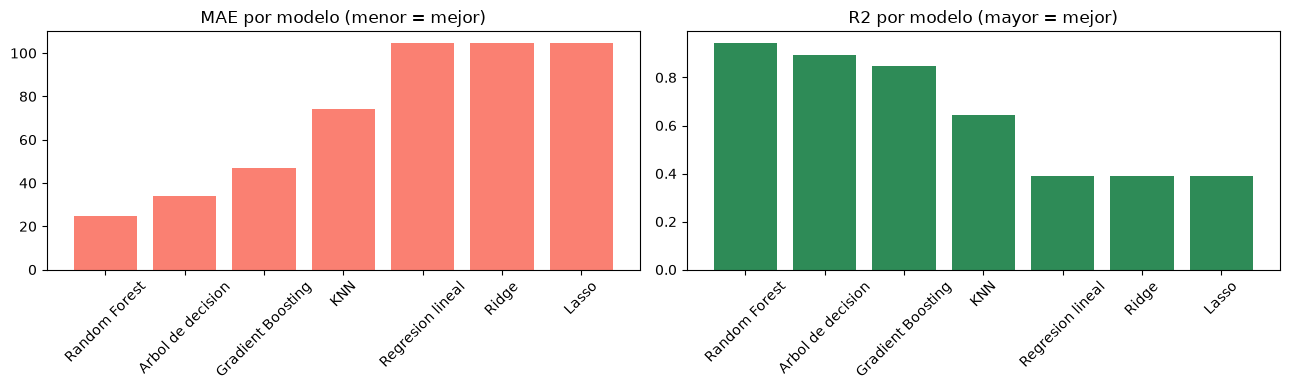

In [6]:
# Grafico comparativo
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
orden = tabla1["Modelo"]
ax[0].bar(orden, tabla1["MAE"], color="salmon")
ax[0].set_title("MAE por modelo (menor = mejor)")
ax[1].bar(orden, tabla1["R2"], color="seagreen")
ax[1].set_title("R2 por modelo (mayor = mejor)")
for a in ax:
    a.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

### Análisis de residuos (opcional)

Los residuos son `valor real - valor predicho`. Se obtienen predicciones fuera de muestra con validación cruzada (5 folds) sobre el mejor modelo, para analizarlos sin sesgo de entrenamiento.

Random Forest (OOF): MAE 25.31 | RMSE 42.53 | R2 0.9450
Residuo medio: -1.32 | Desvio: 42.51

MAE por situacion meteorologica:
 weathersit
1   23.1300
2   25.4500
3   42.4000
4   17.7300

MAE por dia laborable (0=no, 1=si):
 workingday
0   27.8400
1   24.1300

Residuo medio por hora (picos positivos = subestima la demanda):
 hr
0    -1.2000
1    -1.0000
2    -0.9000
3    -0.4000
4    -0.3000
5    -0.2000
6    -1.0000
7    -5.2000
8     5.7000
9    -2.3000
10   -6.9000
11   -3.9000
12    5.4000
13    1.6000
14   -7.2000
15    0.3000
16   -2.7000
17    8.3000
18   -5.4000
19   -5.6000
20   -2.9000
21   -2.2000
22   -1.4000
23   -2.3000


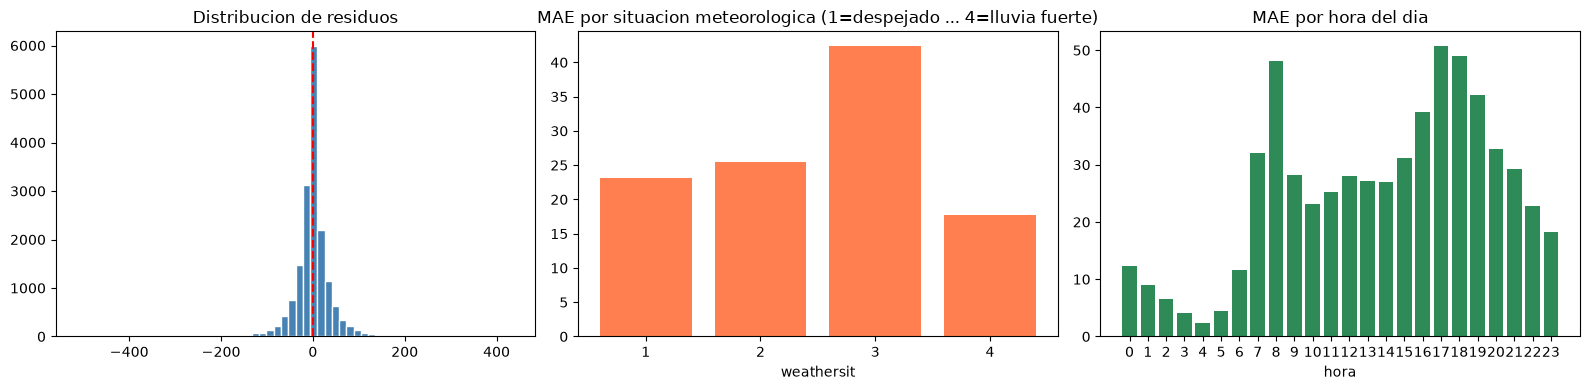

In [7]:
mejor1 = RandomForestRegressor(n_estimators=200, random_state=SEED, n_jobs=-1)
y1_oof = cross_val_predict(mejor1, X1, y1, cv=KFold(5, shuffle=True, random_state=SEED))
resid1 = y1 - y1_oof

print(f"Random Forest (OOF): MAE {mean_absolute_error(y1, y1_oof):.2f} | "
      f"RMSE {np.sqrt(mean_squared_error(y1, y1_oof)):.2f} | R2 {r2_score(y1, y1_oof):.4f}")
print(f"Residuo medio: {resid1.mean():.2f} | Desvio: {resid1.std():.2f}")

res = pd.DataFrame({"residuo": resid1,
                    "weathersit": df_bike["weathersit"],
                    "hr": df_bike["hr"],
                    "workingday": df_bike["workingday"]})

mae_ws = res.groupby("weathersit")["residuo"].apply(lambda s: np.abs(s).mean())
mae_hr = res.groupby("hr")["residuo"].apply(lambda s: np.abs(s).mean())
print("\nMAE por situacion meteorologica:\n", mae_ws.round(2).to_string())
print("\nMAE por dia laborable (0=no, 1=si):\n",
      res.groupby("workingday")["residuo"].apply(lambda s: np.abs(s).mean()).round(2).to_string())
print("\nResiduo medio por hora (picos positivos = subestima la demanda):\n",
      res.groupby("hr")["residuo"].mean().round(1).to_string())

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].hist(resid1, bins=60, color="steelblue", edgecolor="white")
ax[0].axvline(0, color="red", ls="--")
ax[0].set_title("Distribucion de residuos")
ax[1].bar(mae_ws.index.astype(str), mae_ws.values, color="coral")
ax[1].set_title("MAE por situacion meteorologica (1=despejado ... 4=lluvia fuerte)")
ax[1].set_xlabel("weathersit")
ax[2].bar(mae_hr.index.astype(str), mae_hr.values, color="seagreen")
ax[2].set_title("MAE por hora del dia")
ax[2].set_xlabel("hora")
plt.tight_layout(); plt.show()

### Conclusión - Ejercicio 1

**Modelo elegido: Random Forest.** Es el único modelo que logra los mejores valores en las tres métricas simultáneamente: **MAE = 24,72 bicicletas/hora**, **RMSE = 41,80** y **R² = 0,945** sobre el conjunto de prueba. En términos del problema: la predicción se equivoca en promedio unas 25 bicicletas por hora, que representa solo ~13% de la demanda media (189 bicis/h), y explica el 94,5% de la varianza de la demanda. Además, la distancia entre RMSE y MAE no es excesiva, lo que indica que no hay errores catastroficos aislados.

**Ventajas:** no requiere escalar las variables, captura relaciones no lineales e interacciones (por ejemplo, el cruce *hora × día laborable*, que es lo que define los picos de la mañana y la tarde), es robusto ante valores atípicos y ruido, y es resistente a la colinealidad entre `temp` y `atemp`.

**Limitaciones:** es un modelo "caja negra" (no ofrece coeficientes interpretables como la regresión lineal), tarda más en entrenar y predecir, consume más memoria y puede sobreajustar si no se ajustan hiperparámetros (cantidad de árboles, profundidad, mínimo de muestras por hoja). También depende de que los datos de entrenamiento representen los escenarios futuros.

**Lo que muestran las métricas en conjunto:** los modelos lineales (lineal, Ridge y Lasso) dan resultados prácticamente idénticos entre sí y muy malos (**R² ≈ 0,39**, MAE ≈ 105), lo que confirma que la relación entre las variables y la demanda **no es lineal**: elegir el modelo "más simple" o "más interpretable" en este caso sería un error, porque dejaría fuera más de la mitad de la varianza. KNN queda en un punto intermedio (R² = 0,64), el árbol de decisión simple sorprende con R² = 0,893 (pero sobreajusta, ya que en entrenamiento daría R² = 1) y el Gradient Boosting con sus valores por defecto (R² = 0,850) queda por debajo del Random Forest: los hiperparámetros por defecto no siempre son los mejores.

**Análisis de residuos:** el residuo medio está cerca de cero (-1,3), es decir que el modelo no sesga de forma sistemática hacia sobre ni subestimar. Sin embargo, el error **se duplica en días con nube o lluvia** (MAE = 23,1 con cielo despejado frente a 42,4 con lluvia/nieve ligera, `weathersit = 3`), lo cual es esperable: el modelo "aprende" del promedio histórico y en los pocos días de lluvia del dataset tiende a sobreestimar la demanda. En efecto, hay solo **3 registros** con lluvia fuerte (`weathersit = 4`) en todo el dataset, una limitación de los datos. Los errores también se concentran en las **horas pico (17-19 h, MAE entre 42 y 51)**, donde la demanda es más variable, mientras que de madrugada el error es mínimo (MAE < 12).

**Posibles mejoras**
- *Variables:* incluir calendario completo (feriados locales, eventos, clases escolares), probabilidad de lluvia y temperatura real en °C (hoy vienen normalizadas); agregar lag temporales (demanda de la hora anterior / mismo día de la semana anterior).
- *Datos:* aumentar la muestra de días con lluvia y usar un **split temporal** (entrenar con 2011 y evaluar con 2012) en lugar de aleatorio, que es más fiel al uso real.
- *Algoritmos:* probar XGBoost / LightGBM, SVR con kernel RBF o una red neuronal, y realizar búsqueda de hiperparámetros (GridSearchCV / RandomizedSearchCV) sobre el Random Forest, ya que con una sintonía fina probablemente mejorarían todas las métricas.

---

## Ejercicio 2 - Predicción de la potencia eléctrica de una planta de ciclo combinado

**Dataset:** [Combined Cycle Power Plant (UCI)](https://archive.ics.uci.edu/dataset/294/combined+cycle+power+plant) - 9.568 registros de operación de una planta de ciclo combinado (2006-2011), con promedios de 60 minutos.

- **9.568 filas**, 5 columnas.
- **Variable objetivo:** `PE` = potencia neta de salida en MW (media 454,4; desvío 17,1; rango 420-496).
- **Predictores:** `AT` temperatura ambiente (°C), `V` vacío/exhaust (cm Hg), `AP` presión atmosférica (mbar), `RH` humedad relativa (%).

In [8]:
# Carga del dataset desde UCI (archivos .xlsx)
try:
    import openpyxl  # noqa: F401
except ImportError:
    import sys, subprocess
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "openpyxl"])
    import openpyxl

URL_CCPP = "https://archive.ics.uci.edu/static/public/294/combined+cycle+power+plant.zip"

zip_bytes2 = urllib.request.urlopen(URL_CCPP, timeout=90).read()
zf2 = zipfile.ZipFile(io.BytesIO(zip_bytes2))
print("Archivos del zip:", zf2.namelist())

df_ccpp = pd.read_excel(zf2.open("CCPP/Folds5x2_pp.xlsx"))
df_ccpp.head()

Archivos del zip: ['CCPP/', 'CCPP/Folds5x2_pp.ods', 'CCPP/Folds5x2_pp.xlsx', 'CCPP/Readme.txt', 'CCPP/Readme.txt~']


,AT,V,AP,RH,PE
0,14.9600,41.7600,"1,024.0700",73.1700,463.2600
1,25.1800,62.9600,"1,020.0400",59.0800,444.3700
2,5.1100,39.4000,"1,012.1600",92.1400,488.5600
3,20.8600,57.3200,"1,010.2400",76.6400,446.4800
4,10.8200,37.5000,"1,009.2300",96.6200,473.9000


Filas y columnas: (9568, 5)

Nulos por columna:
 AT    0
V     0
AP    0
RH    0
PE    0


,count,mean,std,min,25%,50%,75%,max
AT,"9,568.0000",19.6512,7.4525,1.8100,13.5100,20.3450,25.7200,37.1100
V,"9,568.0000",54.3058,12.7079,25.3600,41.7400,52.0800,66.5400,81.5600
AP,"9,568.0000","1,013.2591",5.9388,992.8900,"1,009.1000","1,012.9400","1,017.2600","1,033.3000"
RH,"9,568.0000",73.3090,14.6003,25.5600,63.3275,74.9750,84.8300,100.1600
PE,"9,568.0000",454.3650,17.0670,420.2600,439.7500,451.5500,468.4300,495.7600



Correlacion lineal con la potencia (PE):
AT   -0.9481
V    -0.8698
RH    0.3898
AP    0.5184


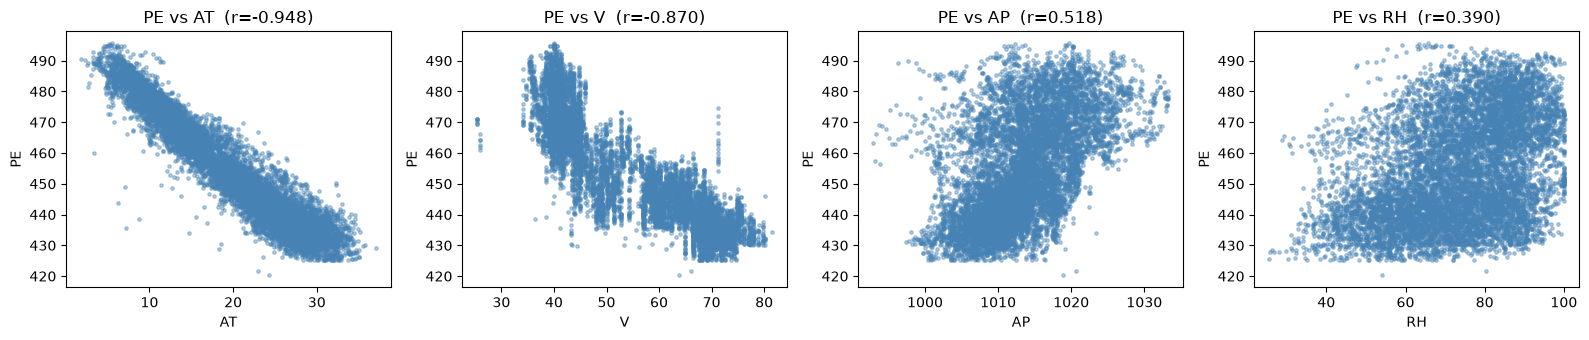

In [9]:
# Exploracion inicial
print("Filas y columnas:", df_ccpp.shape)
print("\nNulos por columna:\n", df_ccpp.isna().sum().to_string())
display(df_ccpp.describe().T)

correl = df_ccpp.corr()["PE"].drop("PE").sort_values()
print("\nCorrelacion lineal con la potencia (PE):")
print(correl.round(4).to_string())

fig, ax = plt.subplots(1, 4, figsize=(16, 3.5))
for a, col in zip(ax, ["AT", "V", "AP", "RH"]):
    a.scatter(df_ccpp[col], df_ccpp["PE"], s=6, alpha=0.4, color="steelblue")
    a.set_xlabel(col); a.set_ylabel("PE")
    a.set_title(f"PE vs {col}  (r={correl[col]:.3f})")
plt.tight_layout(); plt.show()

In [10]:
X2 = df_ccpp.drop(columns=["PE"])
y2 = df_ccpp["PE"]

X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y2, test_size=0.2, random_state=SEED)

print("Train:", X2_train.shape, "| Test:", X2_test.shape)

Train: (7654, 4) | Test: (1914, 4)


### Comparación de modelos (MAE, RMSE, R²)

In [11]:
tabla2 = evaluar_modelos(X2_train, X2_test, y2_train, y2_test,
                         "EJERCICIO 2 - Potencia de la planta (target: PE)")

EJERCICIO 2 - Potencia de la planta (target: PE)


Modelo,MAE,RMSE,R2
Random Forest,2.314,3.230,0.9640
KNN,2.800,3.766,0.9511
Gradient Boosting,2.949,3.829,0.9495
Arbol de decision,3.038,4.447,0.9318
Ridge,3.596,4.503,0.9301
Regresion lineal,3.596,4.503,0.9301
Lasso,3.946,4.943,0.9158


| Modelo | MAE | RMSE | R2 |
|---|---|---|---|
| Random Forest | 2.3136 | 3.2304 | 0.9640 |
| KNN | 2.8004 | 3.7661 | 0.9511 |
| Gradient Boosting | 2.9487 | 3.8287 | 0.9495 |
| Arbol de decision | 3.0383 | 4.4468 | 0.9318 |
| Ridge | 3.5959 | 4.5025 | 0.9301 |
| Regresion lineal | 3.5959 | 4.5026 | 0.9301 |
| Lasso | 3.9461 | 4.9431 | 0.9158 |


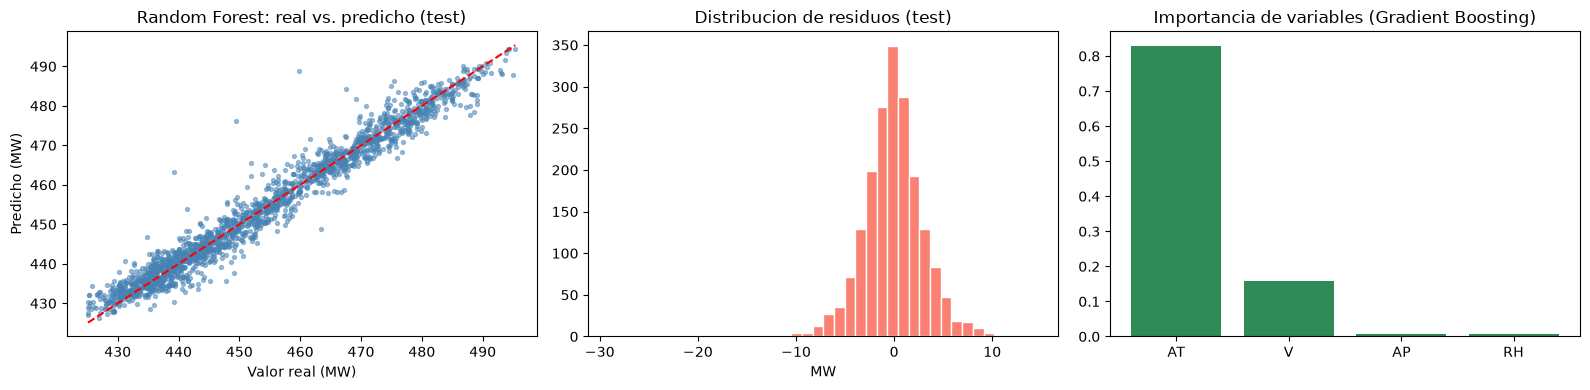

Importancias:
 AT   0.8289
V    0.1576
AP   0.0073
RH   0.0062


In [12]:
# Mejor modelo: valores reales vs. predichos + importancia de variables
mejor2 = RandomForestRegressor(n_estimators=200, random_state=SEED, n_jobs=-1)
mejor2.fit(X2_train, y2_train)
y2_pred = mejor2.predict(X2_test)

gb2 = GradientBoostingRegressor(random_state=SEED).fit(X2_train, y2_train)
imp = pd.Series(gb2.feature_importances_, index=X2.columns).sort_values(ascending=False)

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].scatter(y2_test, y2_pred, s=8, alpha=0.5, color="steelblue")
lims = [min(y2_test.min(), y2_pred.min()), max(y2_test.max(), y2_pred.max())]
ax[0].plot(lims, lims, "r--")
ax[0].set_xlabel("Valor real (MW)"); ax[0].set_ylabel("Predicho (MW)")
ax[0].set_title("Random Forest: real vs. predicho (test)")
ax[1].hist(y2_test - y2_pred, bins=40, color="salmon", edgecolor="white")
ax[1].set_title("Distribucion de residuos (test)")
ax[1].set_xlabel("MW")
ax[2].bar(imp.index, imp.values, color="seagreen")
ax[2].set_title("Importancia de variables (Gradient Boosting)")
plt.tight_layout(); plt.show()

print("Importancias:\n", imp.round(4).to_string())

### Conclusión - Ejercicio 2

**Modelo elegido: Random Forest.** Nuevamente obtiene el mejor resultado en las tres métricas: **MAE = 2,31 MW**, **RMSE = 3,23 MW** y **R² = 0,964** sobre el conjunto de prueba. Puesto en contexto: la planta produce en promedio **454,4 MW** con un desvío estándar de 17,1 MW, así que el error promedio de 2,31 MW equivale a apenas **0,5% de la potencia media** y es unas 7 veces menor que la variabilidad natural de los datos. El gráfico de valores reales vs. predichos muestra que los puntos se ubican muy cerca de la recta identidad, sin desvíos sistemáticos.

**Ventajas:** alta precisión, tolerancia al ruido y a los valores atípicos, no requiere escalar las variables ni asumir linealidad, y las predicciones se obtienen rápidamente una vez entrenado. **Limitaciones:** menor interpretabilidad que un modelo lineal (no entrega una ecuación que se pueda explicar al operador de la planta) y mayor costo computacional; además, al ser un promedio de árboles, puede subestimar valores extremos de potencia.

**¿Qué variable ambiental influye más?** La **temperatura ambiente (`AT`)**, con una correlación de **-0,948** con la potencia (la más alta en valor absoluto) y una importancia de ~83% en el modelo de Gradient Boosting: **a mayor temperatura, menor potencia generada**, porque la turbina de gas rinde menos con aire caliente y el ciclo pierde eficiencia. La segunda variable en importancia es el vacío (`V`, r = -0,870), seguida de la presión atmosférica (`AP`, r = +0,518) y la humedad relativa (`RH`, r = +0,390).

**Lo que muestran las métricas en conjunto:** a diferencia del Ejercicio 1, aquí **todos los modelos funcionan bien** (R² entre 0,916 y 0,964), porque la relación entre las entradas y la potencia es mayormente lineal: la regresión lineal pura ya alcanza R² = 0,930 y MAE = 3,60 MW. Aun así, los modelos no lineales mejoran el ajuste porque capturan la caída no estrictamente lineal de la eficiencia a altas temperaturas. Si el criterio fuese la interpretabilidad y la simplicidad por sobre la precisión mínima, la regresión lineal sería una alternativa razonable (aunque con un RMSE ~39% mas alto), pero dado que la diferencia de costo computacional es despreciable y el problema exige la mayor exactitud posible, **se elige el Random Forest**.

**Posibles mejoras**
- *Variables:* incorporar variables de operación y demanda (carga solicitada, modo de control, encendido/apagado de unidades), datos horarios en lugar de promedios de 60 minutos, y mediciones de otras unidades de la planta.
- *Datos:* trabajar con series de tiempo completas (para detectar degradación de equipos a lo largo del tiempo) y verificar si hay estacionalidad anual no capturada.
- *Algoritmos:* ajustar hiperparámetros con validación cruzada (GridSearchCV / RandomizedSearchCV), comparar con SVR, XGBoost o una red neuronal, y analizar los residuos por temperatura para comprobar que no queda ningún patrón sistemático pendiente.